# 第 07 章　动手微调：在 Mac 上只训练连接器

前面 6 章都在"看"模型。这一章**改**模型：冻结视觉编码器（SigLIP）和语言模型，只训练第 04 章的连接器（一个 12288→576 的线性层，约 708 万参数，占全模型的 2.8%），然后观察：

| 步骤 | 内容 |
|---|---|
| 1 | 生成一个合成数据集：彩色图形 + 标准答案 |
| 2 | 训练前：模型能答对多少？ |
| 3 | 冻结参数、缓存视觉特征、构造"只在答案上算损失"的训练样本 |
| 4 | 在 MPS 上训练约 1 分钟 |
| 5 | 训练后：准确率、回答对比 |
| 6 | 连接器到底改了什么：权重变化、图像 token 的变化、Logit Lens 对比 |
| 7 | 副作用：真实照片的描述有没有被"带偏"？ |
| 8 | 延伸：LoRA |

**核心问题**：语言模型一个参数都不改，只改"翻译官"，能不能让模型学会一个新任务？

In [1]:
import sys, pathlib  # 路径工具
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "vlmlab").exists())  # 找项目根目录
sys.path.insert(0, str(ROOT))  # 加入导入路径

import time  # 计时
import numpy as np  # 数组
import torch  # PyTorch
import torch.nn as nn  # 网络层
import torch.nn.functional as F  # 函数式接口
import matplotlib.pyplot as plt  # 绘图
from PIL import Image, ImageDraw  # 画图形
from vlmlab import *  # 共享工具

setup_matplotlib()  # 中文字体
seed_everything(0)  # 固定随机种子
device = get_device()  # mps
processor, model = load_smolvlm(device)  # 加载模型
tok = processor.tokenizer  # 分词器
vm, conn, lm = model.model.vision_model, model.model.connector, model.model.text_model  # 三大部件
proj = conn.modality_projection.proj  # 要训练的线性层
n_total = sum(p.numel() for p in model.parameters())  # 全部参数
print(f"连接器参数 {proj.weight.numel()/1e6:.2f}M / 全模型 {n_total/1e6:.1f}M = {proj.weight.numel()/n_total:.1%}")  # 打印占比

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

连接器参数 7.08M / 全模型 256.5M = 2.8%


## 1. 合成数据集
每张图是 512×512 的浅色背景，上面画一个随机大小、随机位置的图形：
- 形状：圆形、正方形、三角形
- 颜色：红、绿、蓝、黄、紫、橙

问题固定为 `What shape and color is the object?`，标准答案形如 `A red circle.` / `An orange square.`。

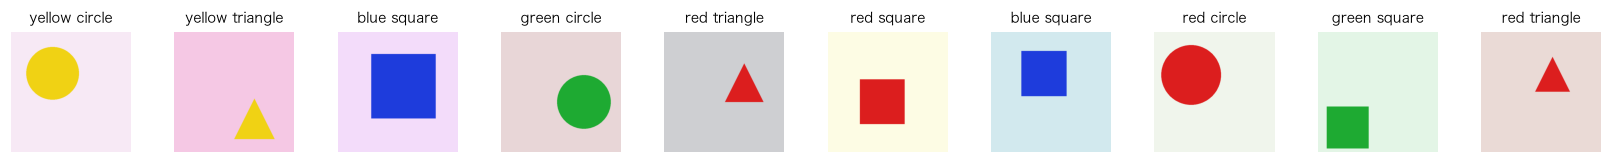

In [2]:
SHAPES = ["circle", "square", "triangle"]  # 3 种形状
COLORS = {"red": (220, 30, 30), "green": (30, 170, 50), "blue": (30, 60, 220),  # 6 种颜色的 RGB
          "yellow": (240, 210, 20), "purple": (140, 40, 180), "orange": (250, 130, 20)}  # 续
QUESTION = "What shape and color is the object?"  # 固定问题

def make_sample(rng):  # 生成一个样本：(图片, 形状, 颜色)
    shape = SHAPES[int(rng.integers(len(SHAPES)))]  # 随机形状
    color = list(COLORS)[int(rng.integers(len(COLORS)))]  # 随机颜色
    bg = tuple(int(v) for v in rng.integers(200, 256, 3))  # 随机浅色背景
    img = Image.new("RGB", (512, 512), bg)  # 画布
    d = ImageDraw.Draw(img)  # 画笔
    r = int(rng.integers(70, 160))  # 大小
    cx, cy = (int(v) for v in rng.integers(r + 10, 512 - r - 10, 2))  # 位置
    box = [cx - r, cy - r, cx + r, cy + r]  # 外接框
    if shape == "circle":  # 圆
        d.ellipse(box, fill=COLORS[color])  # 画圆
    elif shape == "square":  # 方
        d.rectangle(box, fill=COLORS[color])  # 画方
    else:  # 三角
        d.polygon([(cx, cy - r), (cx - r, cy + r), (cx + r, cy + r)], fill=COLORS[color])  # 画三角
    return img, shape, color  # 返回

train = [make_sample(np.random.default_rng(1000 + i)) for i in range(320)]  # 训练集 320 张
test = [make_sample(np.random.default_rng(9000 + i)) for i in range(60)]  # 测试集 60 张（不同的随机种子，与训练集不重复）
show_images([s[0] for s in train[:10]], titles=[f"{c} {s}" for _, s, c in train[:10]], cols=10, size=1.5)  # 看看样本

## 2. 训练前：模型能答对多少？
用第 06 章的贪心生成回答测试集，只要回答里包含正确的形状词 / 颜色词就算对。

In [3]:
def ask(img, max_new=12):  # 问一张图，返回回答文本
    inp = build_inputs(processor, img, QUESTION, split=False)  # 预处理
    with torch.no_grad():  # 不要梯度
        out = model.generate(**inp, max_new_tokens=max_new, do_sample=False)  # 贪心生成
    return tok.decode(out[0, inp["input_ids"].shape[1]:], skip_special_tokens=True).strip()  # 只要新生成的部分

def evaluate(samples):  # 在一组样本上评估
    answers = [ask(img) for img, _, _ in samples]  # 逐张提问
    shape_ok = [s in a.lower() for a, (_, s, _) in zip(answers, samples)]  # 形状对不对
    color_ok = [c in a.lower() for a, (_, _, c) in zip(answers, samples)]  # 颜色对不对
    return answers, np.mean(shape_ok), np.mean(color_ok), np.mean(np.logical_and(shape_ok, color_ok))  # 回答、三种准确率

t = time.time()  # 计时
ans_before, s_acc, c_acc, both_acc = evaluate(test)  # 训练前评估
print(f"训练前（{time.time()-t:.0f} 秒）：形状 {s_acc:.0%}，颜色 {c_acc:.0%}，两者都对 {both_acc:.0%}")  # 打印
for a, (_, s, c) in list(zip(ans_before, test))[:8]:  # 看几个回答
    print(f"  正确：{c:6s} {s:8s} → 模型：{a!r}")  # 对比

训练前（10 秒）：形状 48%，颜色 73%，两者都对 22%
  正确：green  square   → 模型：'The object is green.'
  正确：yellow circle   → 模型：'The object is yellow.'
  正确：orange square   → 模型：'The object is an orange square.'
  正确：orange triangle → 模型：'The object is orange.'
  正确：purple triangle → 模型：'The object is a triangle.'
  正确：green  square   → 模型：'The object is a square.'
  正确：blue   square   → 模型：'The object is a square.'
  正确：purple triangle → 模型：'The object is purple.'


## 3. 准备训练
### 3.1 冻结：只让连接器的权重可训练
`requires_grad_(False)` 让参数不再计算梯度，优化器也就不会改它。注意：**梯度仍然会"流过"冻结的语言模型**，才能传回连接器。

In [4]:
model.requires_grad_(False)  # 先冻结全部参数
proj.weight.requires_grad_(True)  # 只放开连接器的线性层
trainable = [n for n, p in model.named_parameters() if p.requires_grad]  # 列出可训练参数
print("可训练参数:", trainable)  # 只有一个
W0 = proj.weight.detach().clone()  # 保存训练前的权重，之后用来对比和还原

可训练参数: ['model.connector.modality_projection.proj.weight']


### 3.2 缓存视觉特征
SigLIP 被冻结，同一张图每次算出的特征都一样，所以**提前算一次存起来**，训练时直接用，省掉 2/3 的计算量。320 张图 × `[1024, 768]`，用 float16 存约 0.5 GB。

In [5]:
def vision_features(imgs, bs=16):  # 批量计算视觉编码器输出
    out = []  # 收集结果
    for i in range(0, len(imgs), bs):  # 每批 bs 张
        pv = torch.cat([processor.image_processor(images=[im], return_tensors="pt", do_image_splitting=False)["pixel_values"][:, 0] for im in imgs[i:i + bs]]).to(device)  # 预处理成 [bs,3,512,512]
        with torch.no_grad():  # 不要梯度
            out.append(vm(pixel_values=pv).last_hidden_state.half())  # [bs,1024,768]，转 float16 省内存
    return torch.cat(out)  # 拼起来

t = time.time()  # 计时
feats_train = vision_features([s[0] for s in train])  # 训练集特征
print(f"缓存视觉特征 {tuple(feats_train.shape)}，{feats_train.numel()*2/1e9:.2f} GB，用时 {time.time()-t:.0f} 秒")  # 打印

缓存视觉特征 (320, 1024, 768)，0.50 GB，用时 23 秒


### 3.3 训练样本：只在答案上算损失
一条训练序列 = 提问部分（含 64 个图像位置）+ 答案。语言模型的训练目标是"预测下一个 token"，但我们只希望它学**答案**，不需要学提问部分。做法：把提问部分的标签设为 `-100`，`cross_entropy` 会忽略这些位置。

下面把一条样本的输入和标签对齐打印出来（只看末尾）。

In [6]:
prompt = processor.apply_chat_template([{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": QUESTION}]}], add_generation_prompt=True)  # 提问模板
prompt_ids = processor(text=prompt, images=[train[0][0]], return_tensors="pt", do_image_splitting=False)["input_ids"][0].to(device)  # 提问部分的 token（所有样本都一样）
img_pos = (prompt_ids == model.config.image_token_id).nonzero()[:, 0]  # 64 个图像位置
def answer_text(s, c):  # 标准答案文本：元音开头的颜色用 An（An orange circle.）
    return f" {'An' if c[0] in 'aeiou' else 'A'} {c} {s}.<end_of_utterance>"  # 以结束符收尾，模型学会"答完就停"

answers = [tok(answer_text(s, c), add_special_tokens=False, return_tensors="pt").input_ids[0].to(device) for _, s, c in train]  # 每个样本的答案 token
PAD = tok.pad_token_id if tok.pad_token_id is not None else 0  # 填充用的 token

def make_batch(idx):  # 把若干样本拼成一个 batch
    L = max(len(answers[i]) for i in idx)  # 本批最长答案
    ids = torch.stack([torch.cat([prompt_ids, F.pad(answers[i], (0, L - len(answers[i])), value=PAD)]) for i in idx])  # 提问 + 答案 + 右侧填充
    labels = torch.full_like(ids, -100)  # 默认都忽略
    for b, i in enumerate(idx):  # 逐条
        labels[b, len(prompt_ids):len(prompt_ids) + len(answers[i])] = answers[i]  # 只有答案位置有标签
    return ids, labels  # 返回

ids, labels = make_batch([0])  # 看第 0 条
print(f"{'位置':>4s}  {'输入 token':22s} {'标签（-100=不算损失）'}")  # 表头
for p in range(ids.shape[1] - 9, ids.shape[1]):  # 最后 9 个位置
    print(f"{p:>4d}  {tok.convert_ids_to_tokens(ids[0, p].item())!r:22s} {labels[0, p].item() if labels[0, p] < 0 else repr(tok.convert_ids_to_tokens(labels[0, p].item()))}")  # 打印

  位置  输入 token               标签（-100=不算损失）
  79  'Ċ'                    -100
  80  'Ass'                  -100
  81  'istant'               -100
  82  ':'                    -100
  83  'ĠA'                   'ĠA'
  84  'Ġyellow'              'Ġyellow'
  85  'Ġcircle'              'Ġcircle'
  86  '.'                    '.'
  87  '<end_of_utterance>'   '<end_of_utterance>'


注意"预测下一个"的错位：第 t 个位置的输出要去预测第 t+1 个 token，所以计算损失时用 `logits[:, :-1]` 对齐 `labels[:, 1:]`。

### 3.4 前向函数：用"可训练的连接器"替换图像 token
和第 05 章一样手动拼接：词向量 → 在 64 个图像位置填入连接器的输出 → 语言模型 → lm_head。

In [7]:
def forward_loss(idx):  # 一个 batch 的损失
    ids, labels = make_batch(idx)  # 构造输入和标签
    img_tokens = conn(feats_train[idx].float())  # 连接器（可训练）：[B,1024,768] → [B,64,576]
    emb = lm.embed_tokens(ids).clone()  # 查词向量（冻结）
    emb[:, img_pos] = img_tokens  # 填入图像 token
    h = lm(inputs_embeds=emb).last_hidden_state  # 语言模型（冻结，但梯度会穿过它）
    logits = model.lm_head(h[:, :-1])  # 每个位置预测下一个 token
    return F.cross_entropy(logits.reshape(-1, logits.shape[-1]), labels[:, 1:].reshape(-1), ignore_index=-100)  # 只在答案位置算交叉熵

with torch.no_grad():  # 先看看训练前的损失
    print(f"训练前的损失（随机 32 条）：{forward_loss(np.arange(32)).item():.3f}")  # 打印

训练前的损失（随机 32 条）：1.565


## 4. 训练
AdamW，学习率 1e-4，每批 16 条，训练 120 步（约 6 个 epoch）。每 10 步在**测试集**上算一次损失，观察有没有过拟合。

第   0 步  训练损失 1.6793  测试损失 0.6905  已用 1 秒


第  10 步  训练损失 0.0261  测试损失 0.0232  已用 5 秒


第  20 步  训练损失 0.0045  测试损失 0.0036  已用 10 秒


第  30 步  训练损失 0.0018  测试损失 0.0015  已用 14 秒


第  40 步  训练损失 0.0014  测试损失 0.0010  已用 18 秒


...

第  80 步  训练损失 0.0008  测试损失 0.0005  已用 35 秒


第  90 步  训练损失 0.0005  测试损失 0.0005  已用 39 秒


第 100 步  训练损失 0.0004  测试损失 0.0004  已用 44 秒


第 110 步  训练损失 0.0004  测试损失 0.0004  已用 48 秒


第 119 步  训练损失 0.0004  测试损失 0.0004  已用 52 秒


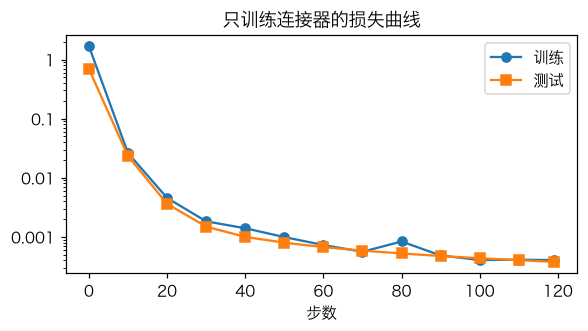

In [8]:
feats_test = vision_features([s[0] for s in test])  # 测试集特征也缓存一下
answers_train = answers  # 先保存训练集答案
answers_test = [tok(answer_text(s, c), add_special_tokens=False, return_tensors="pt").input_ids[0].to(device) for _, s, c in test]  # 测试集答案

def test_loss():  # 测试集损失
    global answers, feats_train  # 临时切换数据源（为了复用 forward_loss）
    a_bak, f_bak = answers, feats_train  # 备份
    answers, feats_train = answers_test, feats_test  # 换成测试集
    with torch.no_grad():  # 不要梯度
        loss = forward_loss(np.arange(len(test))).item()  # 计算
    answers, feats_train = a_bak, f_bak  # 换回来
    return loss  # 返回

opt = torch.optim.AdamW([proj.weight], lr=1e-4, weight_decay=0.0)  # 只优化连接器
rng = np.random.default_rng(0)  # 采样用的随机数
log = {"step": [], "train": [], "test": []}  # 记录
t = time.time()  # 计时
for step in range(120):  # 训练循环
    loss = forward_loss(rng.integers(0, len(train), 16))  # 随机抽 16 条
    opt.zero_grad()  # 清梯度
    loss.backward()  # 反向传播：梯度从损失 → lm_head → 30 层语言模型 → 连接器
    opt.step()  # 更新连接器
    if step % 10 == 0 or step == 119:  # 定期记录
        log["step"].append(step)  # 步数
        log["train"].append(loss.item())  # 训练损失
        log["test"].append(test_loss())  # 测试损失
        print(f"第 {step:3d} 步  训练损失 {log['train'][-1]:.4f}  测试损失 {log['test'][-1]:.4f}  已用 {time.time()-t:.0f} 秒")  # 打印
W1 = proj.weight.detach().clone()  # 保存训练后的权重

plt.figure(figsize=(6, 2.8))  # 画布
plt.plot(log["step"], log["train"], "o-", label="训练")  # 训练曲线
plt.plot(log["step"], log["test"], "s-", label="测试")  # 测试曲线
log_y()  # 对数坐标
plt.xlabel("步数")  # 横轴
plt.legend()  # 图例
plt.title("只训练连接器的损失曲线")  # 标题
plt.show()  # 显示

## 5. 训练后：准确率
用和训练前完全相同的方式在测试集上生成回答。

训练前：形状 48%，颜色 73%，两者都对 22%
训练后：形状 100%，颜色 100%，两者都对 100%


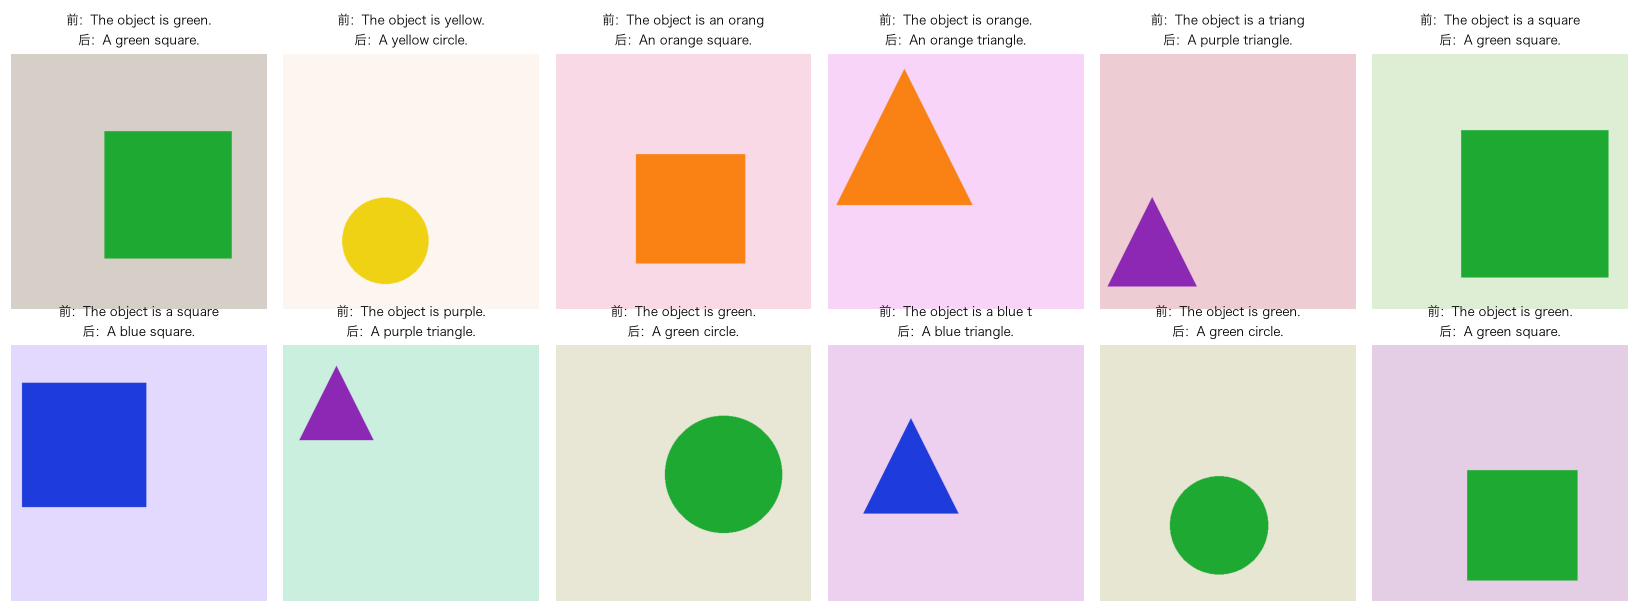

In [9]:
ans_after, s_acc2, c_acc2, both_acc2 = evaluate(test)  # 训练后评估
print(f"训练前：形状 {s_acc:.0%}，颜色 {c_acc:.0%}，两者都对 {both_acc:.0%}")  # 对比
print(f"训练后：形状 {s_acc2:.0%}，颜色 {c_acc2:.0%}，两者都对 {both_acc2:.0%}")  # 对比
fig, axes = plt.subplots(2, 6, figsize=(15, 5.6))  # 12 个例子
for ax, (img, s, c), a0, a1 in zip(axes.flat, test, ans_before, ans_after):  # 遍历
    ax.imshow(img)  # 图片
    ax.axis("off")  # 去坐标轴
    ax.set_title(f"前：{a0[:22]}\n后：{a1[:22]}", fontsize=8)  # 训练前后的回答
plt.tight_layout()  # 调整
plt.show()  # 显示

## 6. 连接器到底改了什么？
### 6.1 权重变化
比较训练前后的权重 $W_0$、$W_1$。第 04 章说过，12288 维 = 4×4 个 patch 位置 × 768 维，可以按块内位置拆开看变化量。

相对变化 ‖ΔW‖/‖W₀‖ = 3.27%


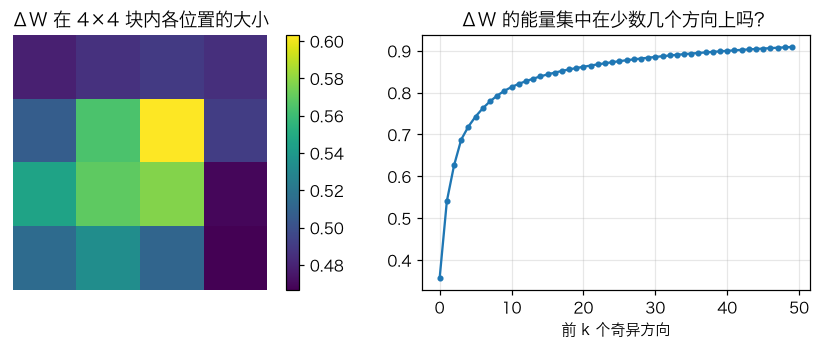

前 8 个奇异方向占 ΔW 能量的 78%


In [10]:
dW = (W1 - W0).float()  # 权重变化
print(f"相对变化 ‖ΔW‖/‖W₀‖ = {dW.norm() / W0.norm():.2%}")  # 只改了很小一部分
pos_change = dW.view(576, 16, 768).norm(dim=(0, 2)).view(4, 4).cpu()  # 每个块内位置的变化量
U, S, V = torch.linalg.svd(dW.cpu(), full_matrices=False)  # 奇异值分解：看变化是不是"低秩"的
fig, axes = plt.subplots(1, 2, figsize=(10, 3))  # 两个子图
im = axes[0].imshow(pos_change, cmap="viridis")  # 4×4 热力图
axes[0].set_title("ΔW 在 4×4 块内各位置的大小")  # 标题
axes[0].axis("off")  # 去坐标轴
plt.colorbar(im, ax=axes[0])  # 色条
axes[1].plot((S ** 2).cumsum(0)[:50] / (S ** 2).sum(), "o-", ms=3)  # 前 50 个奇异值的累计能量
axes[1].set_xlabel("前 k 个奇异方向")  # 横轴
axes[1].set_title("ΔW 的能量集中在少数几个方向上吗？")  # 标题
axes[1].grid(alpha=0.3)  # 网格
plt.show()  # 显示
print(f"前 8 个奇异方向占 ΔW 能量的 {(S[:8]**2).sum()/(S**2).sum():.0%}")  # 打印

如果 ΔW 的能量集中在少数几个方向上，说明这次微调本质上是**低秩**的。这正是 LoRA 的出发点（第 8 节）。

**观察**：4×4 块内各位置的变化量差别不大，中间几格稍大。奇异值曲线显示第 1 个方向就占了约 40% 的能量，前 8 个方向占约 80%。

### 6.2 同一张图，图像 token 变成了什么？
取一张测试图，分别用 $W_0$、$W_1$ 计算 64 个图像 token，比较 PCA 着色、长度和"最近的词"（第 04 章的方法）。

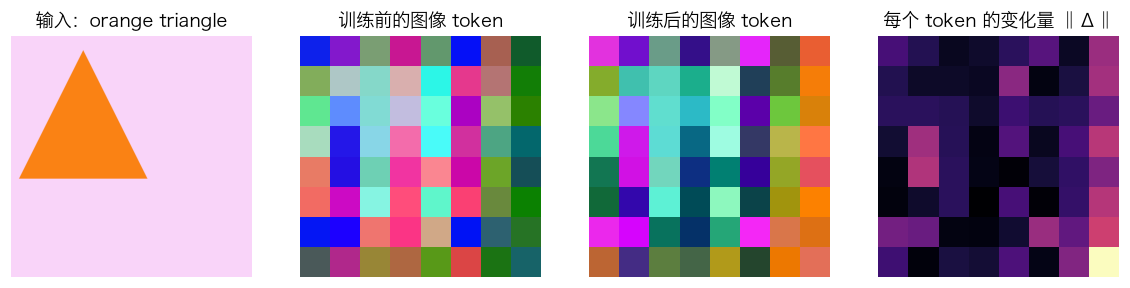

训练前：长度中位数 107.0，最近的词（前 16 个）：['�', '�', '型', '化', 'optics', '化', '的', '�', '的', '的', '型', 'ureth', '型', 'ureth', 'ureth', 'rect']，最高相似度 0.21
训练后：长度中位数 110.3，最近的词（前 16 个）：['下', '�', '型', 'detergents', 'Copy', '化', '的', 'RECT', '的', '的', '型', 'ureth', '型', 'ureth', 'ureth', 'detergents']，最高相似度 0.21


In [11]:
k = 3  # 选第 3 张测试图
img, s, c = test[k]  # 图和答案
E = lm.embed_tokens.weight.detach()  # 词向量表
def tokens_with(W):  # 用指定权重计算这张图的 64 个图像 token
    proj.weight.data.copy_(W)  # 换权重
    with torch.no_grad():  # 不要梯度
        return conn(feats_test[k:k + 1].float())[0]  # [64,576]
tok0, tok1 = tokens_with(W0), tokens_with(W1)  # 训练前、后
proj.weight.data.copy_(W1)  # 恢复为训练后的权重
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))  # 四个子图
axes[0].imshow(img)  # 原图
axes[0].set_title(f"输入：{c} {s}")  # 标题
axes[1].imshow(pca_rgb(tok0), interpolation="nearest")  # 训练前 PCA
axes[1].set_title("训练前的图像 token")  # 标题
axes[2].imshow(pca_rgb(tok1), interpolation="nearest")  # 训练后 PCA
axes[2].set_title("训练后的图像 token")  # 标题
axes[3].imshow((tok1 - tok0).norm(dim=-1).reshape(8, 8).cpu(), cmap="magma", interpolation="nearest")  # 变化量
axes[3].set_title("每个 token 的变化量 ‖Δ‖")  # 标题
for ax in axes:  # 去坐标轴
    ax.axis("off")  # 关闭
plt.show()  # 显示
for name, tk in [("训练前", tok0), ("训练后", tok1)]:  # 最近的词
    best = (F.normalize(tk, dim=-1) @ F.normalize(E, dim=-1).T).max(-1)  # 余弦相似度最高的词
    words = [tok.decode([i]).strip() for i in best.indices.tolist()]  # 解码
    print(f"{name}：长度中位数 {tk.norm(dim=-1).median():.1f}，最近的词（前 16 个）：{words[:16]}，最高相似度 {best.values.max():.2f}")  # 打印

### 6.3 Logit Lens 对比：颜色词和形状词出现在哪里？
第 05 章的方法：把语言模型最后一层在 64 个图像位置上的输出解码成词，看正确的颜色词和形状词的概率分布在哪些格子上。

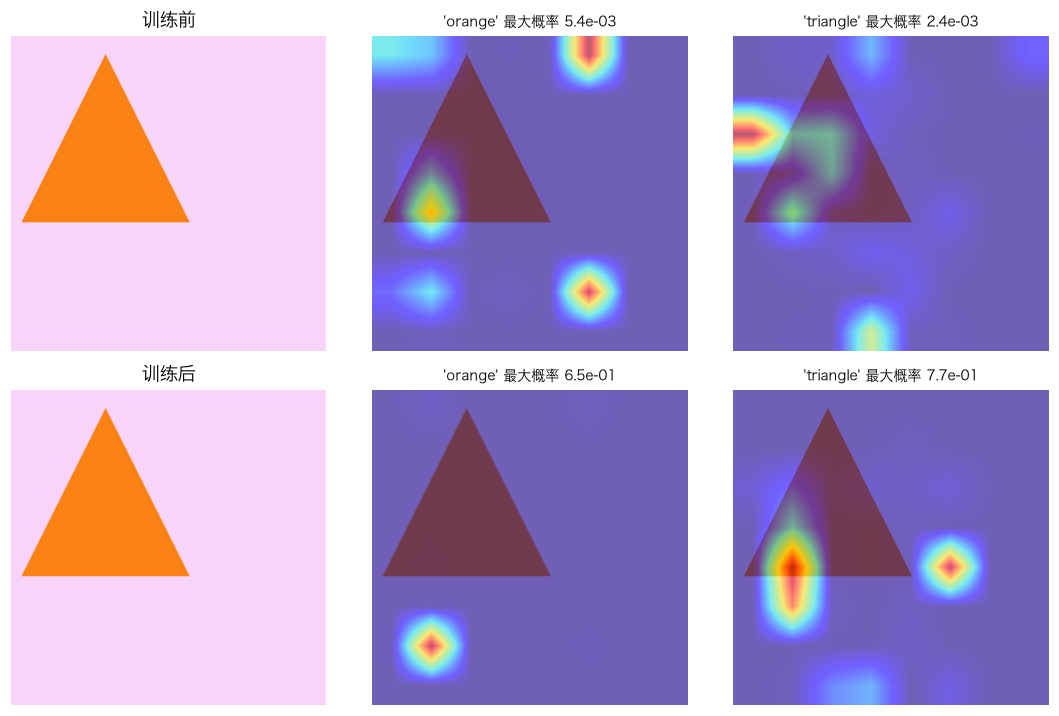

In [12]:
def lens_maps(W, words):  # 用权重 W 跑一遍，返回各个词在 64 个图像位置上的概率
    proj.weight.data.copy_(W)  # 换权重
    inp = build_inputs(processor, img, QUESTION, split=False)  # 预处理
    with torch.no_grad():  # 不要梯度
        p = model(**inp).logits[0, img_pos].softmax(-1)  # logits 就是"最后一层 → final norm → lm_head"，取 64 个图像位置，得到词概率
    return [p[:, tok.encode(" " + w, add_special_tokens=False)[0]].reshape(8, 8).cpu() for w in words]  # 每个词一张 8×8 图

words = [c, s]  # 正确的颜色词和形状词
maps0, maps1 = lens_maps(W0, words), lens_maps(W1, words)  # 训练前后
proj.weight.data.copy_(W1)  # 恢复为训练后的权重
fig, axes = plt.subplots(2, 3, figsize=(10, 6.6))  # 2 行 3 列
for r, (name, maps) in enumerate([("训练前", maps0), ("训练后", maps1)]):  # 每行一个状态
    axes[r, 0].imshow(img)  # 原图
    axes[r, 0].set_title(name)  # 标题
    axes[r, 0].axis("off")  # 去坐标轴
    for col, (w, m) in enumerate(zip(words, maps), 1):  # 每个词
        overlay(img, m, ax=axes[r, col], title=f"'{w}' 最大概率 {m.max():.1e}")  # 叠加
plt.tight_layout()  # 调整
plt.show()  # 显示

一张图说明不了问题。下面在全部 60 张测试图上统计：训练后，正确颜色词概率最高的那一格，有多少比例落在图形上？作为对照，计算"随便选一格落在图形上"的概率（即图形覆盖的格子比例）。

In [13]:
def object_cells(img):  # 8×8 网格里，哪些格子有一半以上的像素属于图形
    a = torch.from_numpy(np.asarray(img).astype(np.float32))  # [512,512,3]
    mask = ((a - a[0, 0]).abs().sum(-1) > 30).float()  # 和左上角背景色差别大的像素属于图形
    return mask.view(8, 64, 8, 64).mean((1, 3)) > 0.5  # 每个 64×64 格子里图形像素的比例 > 0.5

proj.weight.data.copy_(W1)  # 用训练后的权重
hit, chance = [], []  # 命中与随机基准
for img_t, s_t, c_t in test:  # 逐张测试图
    inp = build_inputs(processor, img_t, QUESTION, split=False)  # 预处理
    with torch.no_grad():  # 不要梯度
        p = model(**inp).logits[0, img_pos].softmax(-1)  # 64 个图像位置的词概率
    m = p[:, tok.encode(" " + c_t, add_special_tokens=False)[0]]  # 正确颜色词的概率
    obj = object_cells(img_t).flatten()  # 64 个格子是否属于图形
    hit.append(bool(obj[m.argmax().item()]))  # 最高概率的格子在不在图形上
    chance.append(obj.float().mean().item())  # 随机选一格落在图形上的概率
print(f"颜色词概率最高的格子落在图形上的比例：{np.mean(hit):.0%}（随机选格子的基准：{np.mean(chance):.0%}）")  # 打印

颜色词概率最高的格子落在图形上的比例：20%（随机选格子的基准：15%）


**观察**：训练后，正确颜色词和形状词的最大概率从 1e-3 量级升到 0.7～0.8，但**最亮的格子往往在背景上，而不在图形所在的位置**。上面在 60 张测试图上的统计也印证了这一点：最高概率的格子落在图形上的比例，只比随机选格子略高一点。

也就是说，连接器并没有学会"在物体的位置上标注它是什么"，而是把答案写进了某几个背景 token。一种可能的解释：SigLIP 深层的背景 token 通过全局注意力汇总了整张图的信息（第 03 章的离群 token 就在背景上），对这个任务来说，从它们那里"读出答案"最省事。这也提醒我们：**模型学到的解法不一定是人以为的那种。**

## 7. 副作用：真实照片还认得吗？
连接器是所有图片共用的。只用合成图形训练后，再让它描述第 02～06 章的那张牛肉饭照片，看看有没有被"带偏"。

In [14]:
photo = load_photo()  # 原来的照片
for name, W in [("训练前", W0), ("训练后", W1)]:  # 两种权重
    proj.weight.data.copy_(W)  # 换权重
    inp = build_inputs(processor, photo, "Describe this image.", split=False)  # 预处理
    with torch.no_grad():  # 不要梯度
        out = model.generate(**inp, max_new_tokens=40, do_sample=False)  # 生成
    print(f"【{name}】{tok.decode(out[0, inp['input_ids'].shape[1]:], skip_special_tokens=True).strip()}\n")  # 打印

【训练前】An overhead shot shows a bowl of food, likely a seafood dish, with a poached egg nestled within the ingredients. The bowl is filled with a variety of seafood, including:

- A



【训练后】An overhead shot of a traditional Japanese dish, likely a noodle dish, shows a large bowl filled with a variety of ingredients. The bowl is made of a textured, unfinished material, likely wood,



对比两段描述：语言模型一个参数都没改，但只因为连接器变了，描述内容就明显不同。原本说对的细节（比如 poached egg）可能消失，也可能冒出新的错误（本教程两次试跑分别出现过 "bright red egg" 和 "noodle dish"）。

这就是**灾难性遗忘**（catastrophic forgetting）的雏形：只在一个窄任务上训练，模型会把所有输入都往这个任务上"拉"。实际微调时，通常会混入一部分原来的通用数据，或者用更小的学习率、更少的步数、LoRA 来缓解。

最后把连接器还原成原始权重，并确认模型回到了原样。

In [15]:
proj.weight.data.copy_(W0)  # 还原
proj.weight.requires_grad_(False)  # 重新冻结
check_close("连接器已还原", proj.weight, W0, atol=0)  # 确认
print("还原后再问一张测试图:", ask(test[0][0]), "（与训练前的回答应一致：", ans_before[0], "）")  # 对比

✅ 连接器已还原: 形状 (576, 12288)，最大误差 0.00e+00（容差 0e+00）
还原后再问一张测试图: The object is green. （与训练前的回答应一致： The object is green. ）


## 8. 延伸：LoRA
6.1 节看到 ΔW 的能量集中在少数方向上。**LoRA**（Low-Rank Adaptation）干脆规定 ΔW 必须是低秩的：
$$W = W_0 + \frac{\alpha}{r} B A, \quad A \in \mathbb{R}^{r \times 12288},\ B \in \mathbb{R}^{576 \times r}$$
只训练 A 和 B，$W_0$ 不动。r=8 时可训练参数从 708 万降到 10 万。下面是一个最小实现，第 08 章会真正训练它，并和全量训练做对比。

In [16]:
class LoRALinear(nn.Module):  # 给一个冻结的线性层加上低秩旁路
    def __init__(self, base: nn.Linear, r=8, alpha=16):  # base：原线性层；r：秩；alpha：缩放
        super().__init__()  # 父类初始化
        self.base = base  # 原层（冻结）
        self.A = nn.Parameter(torch.randn(r, base.in_features, device=base.weight.device) * 0.01)  # 降维矩阵，小随机数初始化
        self.B = nn.Parameter(torch.zeros(base.out_features, r, device=base.weight.device))  # 升维矩阵，全 0 初始化 → 一开始 ΔW=0，模型不变
        self.scale = alpha / r  # 缩放系数

    def forward(self, x):  # 前向
        return self.base(x) + (x @ self.A.T @ self.B.T) * self.scale  # 原输出 + 低秩修正

lora = LoRALinear(proj, r=8)  # 包装连接器的线性层
x_demo = torch.randn(2, 64, 12288, device=device)  # 随便造一个输入
with torch.no_grad():  # 不要梯度
    check_close("LoRA 初始时输出不变（B=0）", lora(x_demo), proj(x_demo), atol=1e-4)  # 验证
n_lora = sum(p.numel() for p in [lora.A, lora.B])  # LoRA 参数量
print(f"LoRA 可训练参数 {n_lora:,}，是完整连接器的 {n_lora / proj.weight.numel():.1%}")  # 打印
print("用法：conn.modality_projection.proj = lora，然后只把 [lora.A, lora.B] 交给优化器即可。")  # 提示

✅ LoRA 初始时输出不变（B=0）: 形状 (2, 64, 576)，最大误差 0.00e+00（容差 1e-04）
LoRA 可训练参数 102,912，是完整连接器的 1.5%
用法：conn.modality_projection.proj = lora，然后只把 [lora.A, lora.B] 交给优化器即可。


## 小结
- 只训练 2.8% 的参数（连接器），约 1 分钟，模型就学会了一个原来做不好的任务。说明**连接器决定了哪些视觉信息、以什么形式交给语言模型**
- 梯度会穿过冻结的语言模型传回连接器；冻结 ≠ 不参与计算
- 训练只改了连接器权重的一小部分，而且变化集中在少数方向上，这是 LoRA 的依据
- 窄任务微调会带偏通用能力（灾难性遗忘），实际使用要混合数据或控制训练强度

**下一章**：真正训练 LoRA，并比较几种对抗遗忘的办法。